In [12]:
#!apt -qq update
#!apt -qq install -y tesseract-ocr tesseract-ocr-spa
"""
Uncommet previews ubuntu installation dependencies if you are running in colab.
We installed this directly using WSL, since we needed root permissions we ran using direct bash
"""

'\nUncommet previews ubuntu installation dependencies if you are running in colab.\nWe installed this directly using WSL, since we needed root permissions we ran using direct bash\n'

In [13]:
#!pip -q install pytesseract opencv-python-headless pillow

"""
If running in colab, you can uncomment previous line and execute. This example was run using WSL, so we installed 
dependencies directly using uv as fallow: uv add pytesseract opencv-python-headless pillow

So if you need the dependencies again you can exec: uv async in you command line.
"""

'\nIf running in colab, you can uncomment previous line and execute. This example was run using WSL, so we installed \ndependencies directly using uv as fallow: uv add pytesseract opencv-python-headless pillow\n\nSo if you need the dependencies again you can exec: uv async in you command line.\n'

In [14]:
# Preparar Colab
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.pipeline import Pipeline

"""
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

docs = ["película excelente", "película aburrida aburrida"]

# Solo bag of words (conteos crudos)
cv = CountVectorizer()
print(cv.fit_transform(docs).toarray())
# [[0 1 1]    -> columnas: aburrida, excelente, película
#  [2 0 1]]

# Bag of words con pesos TF-IDF
tv = TfidfVectorizer()
print(tv.fit_transform(docs).toarray().round(2))

TfidfVectorizer  ==  CountVectorizer  +  TfidfTransformer
Converte texto en numero, numero es lo que los modelos entienden. 
Crea el bag of word, asigna a cada palabra un numero.

- CountVectorizer 
    > CouCrea el bag of word, es decir, el vocabulario y su conteo.
    > 
- TF-IDF
    > Usa la formula TF-IDF y normaliza, reescala los conteos del bag of word.
    > Otra forma de llenar ese mismo vector, dándole más peso a palabras informativas
"""
from sklearn.feature_extraction.text import TfidfVectorizer

"""
Es un clasificador. Calcula la suma ponderada de las caracteristicas y la pasa por una funcion
sigmoide para obtener una probabilidad.
"""
from sklearn.linear_model import LogisticRegression # para clasificacion numerica

"""
	            Predicho: positivo	        Predicho: negativo
Real: positivo	Verdadero positivo (TP)	    Falso negativo (FN)
Real: negativo	Falso positivo (FP)	        Verdadero negativo (TN)

Precision, Recall y F1
Precision = TP / (TP + FP): de lo que predije como positivo, ¿cuánto lo era realmente?
Recall = TP / (TP + FN): de todos los positivos reales, ¿cuántos encontré?
F1 = media armónica de ambos: $F1 = 2 \cdot \frac{P \cdot R}{P + R}$

¿Por qué no solo accuracy? Si el 95% de tus datos son de una clase, un modelo que siempre
predice esa clase tiene 95% de accuracy y es inútil. F1 es más honesto con clases desbalanceadas.

classification_report te muestra precision, recall y F1 por clase,
y f1_score te da el valor individual (con opciones como average='macro' o 'weighted' para el caso multiclase).
"""
#valuacion, estas son metricas para evaluar que tan bien predice el modelo
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score
)

<>:52: SyntaxWarning: invalid escape sequence '\c'
<>:52: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_205899/1060729295.py:52: SyntaxWarning: invalid escape sequence '\c'
  F1 = media armónica de ambos: $F1 = 2 \cdot \frac{P \cdot R}{P + R}$


In [15]:
# make models iside src importable here. For uv this does not matter,
# or when using .venv, but does matter when using global
from util import make_dir_modules_importable
make_dir_modules_importable()

Adding: /mnt/d/Documents/Ciencias de datos/Ciencia de datos 2/PRACTICAS/uasd-ds-2/unidad02/DEMO02/src to sys.path


In [16]:
# Cargar el corpus público
dataset = load_dataset("cardiffnlp/tweet_eval", "sentiment") # de las varias tareas de TweetEval, usamos la de sentimiento
labels = ["negative", "neutral", "positive"]

"""
Analogía: train es estudiar con los ejercicios del libro, validation son los simulacros donde ajustas tu método de estudio, 
y test es el examen real. Si usaras el examen real para practicar, tu nota ya no reflejaría lo que realmente sabes.
"""
train_df = dataset["train"].to_pandas() # para entrenar
valid_df = dataset["validation"].to_pandas() # para ajustar parametros
test_df = dataset["test"].to_pandas() # para probar al final

print(train_df.shape, valid_df.shape, test_df.shape)
print(train_df["label"].value_counts(normalize=True).sort_index())
print(train_df.columns.tolist())
print(dataset["train"].features['label'].names)
print("Nulos: ", train_df.isna().sum())
print("Duplicados: ", train_df.duplicated().sum())
print(train_df.head())

#Acción concreta. Compruebe que existen las columnas text y label. Interprete la distribución antes de entrenar.

(45615, 2) (2000, 2) (12284, 2)
label
0    0.155497
1    0.453206
2    0.391297
Name: proportion, dtype: float64
['text', 'label']
['negative', 'neutral', 'positive']
Nulos:  text     0
label    0
dtype: int64
Duplicados:  26
                                                text  label
0  "QT @user In the original draft of the 7th boo...      2
1  "Ben Smith / Smith (concussion) remains out of...      1
2  Sorry bout the stream last night I crashed out...      1
3  Chase Headley's RBI double in the 8th inning o...      1
4  @user Alciato: Bee will invest 150 million in ...      2


In [17]:
assert {"text", "label"}.issubset(train_df.columns)
assert {"text", "label"}.issubset(valid_df.columns)
assert {"text", "label"}.issubset(test_df.columns)
print("Esquema validado")


Esquema validado


In [18]:
# Construir el pipeline sin fuga
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True, # transforma a lower
        ngram_range=(1, 2), # se incluyen unigramas y bigramas. ie: good vs "not good"
        min_df=3, # usa las palabras que aparecen al menos 3 frecuencia
        max_features=25_000 # solo toma los 25k terminos mas frequentes en el corpus de entrenamiento, eso luego de aplicar los filtros anteriores
    )),
    ("classifier", LogisticRegression(
        max_iter=1_000,
        class_weight="balanced",
        random_state=42
    ))
])


"""
TF-IDF se ajusta dentro del pipeline utilizando únicamente el conjunto de entrenamiento. 
La validación se reserva para decisiones y la prueba para la evaluación final.
"""
model.fit(train_df["text"], train_df["label"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",3
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",25000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


In [19]:
valid_pred = model.predict(valid_df["text"])
print("F1 macro validación:", f1_score(valid_df["label"], valid_pred, average="macro"))


F1 macro validación: 0.6400919895877831


              precision    recall  f1-score   support

    negative      0.556     0.670     0.608      3972
     neutral      0.652     0.540     0.591      5937
    positive      0.547     0.594     0.569      2375

    accuracy                          0.592     12284
   macro avg      0.585     0.601     0.589     12284
weighted avg      0.601     0.592     0.592     12284



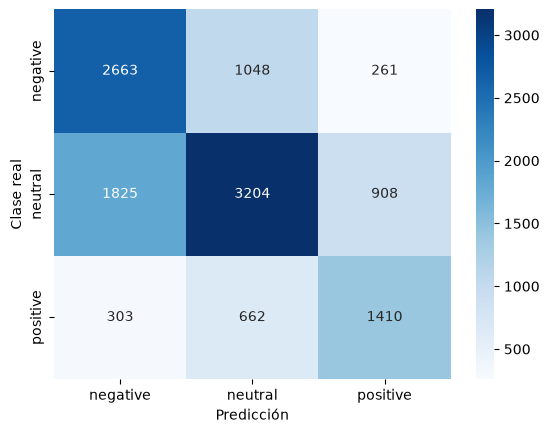

In [20]:
"""
Precision -> De los ejemplos asignados a una clase, cuántos pertenecían realmente a ella.
Recall    -> De los ejemplos reales de una clase, cuántos fueron detectados.
F1        -> Equilibrio entre precision y recall.
F1 macro  -> Promedio que concede el mismo peso a cada clase.
Matriz de confusión -> Muestra qué clases se confunden entre sí.
"""
test_pred = model.predict(test_df["text"])
print(classification_report(test_df["label"], test_pred, target_names=labels, digits=3))
cm = confusion_matrix(test_df["label"], test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicción"); plt.ylabel("Clase real"); plt.show()


In [21]:
errors = test_df.copy()
errors["prediction"] = test_pred
errors = errors[errors["label"] != errors["prediction"]]
errors["real"] = errors["label"].map(dict(enumerate(labels)))
errors["predicted"] = errors["prediction"].map(dict(enumerate(labels)))
errors[["text", "real", "predicted"]].sample(20, random_state=42)


,text,real,predicted
9762,Kate Upton & Justin Verlander: To Hell with Cy...,neutral,negative
5147,The future of online GEO classes and virtual f...,neutral,positive
10987,"Duke is overrated.""Grayson Allen is trash.""UNC...",neutral,negative
8975,Ana Navarro destroys Melania Trump’s cyberbull...,negative,neutral
7433,Australian Government Commits to Nationwide Me...,neutral,negative
9714,👉This map shows the huge span of the Dakota Ac...,neutral,positive
1449,Police: assailant shot after trying to stab se...,neutral,negative
5756,I hear this is the last of #westworld for a wh...,positive,negative
9646,Yesterday #Messi became the 1st player in the ...,positive,neutral
5115,Great @user need to keep a check on this Disas...,negative,positive


### Reflexión
- ¿Qué errores parecen relacionados con negación, ironía o falta de contexto?
- ¿Qué limitación existe al transferir este modelo a textos dominicanos en español?


## Parte B · OCR
El ejemplo crea una imagen controlada, extrae el texto e inspecciona la confianza de cada palabra.


Fuente utilizada: /usr/share/fonts/truetype/dejavu/DejaVuSans.ttf


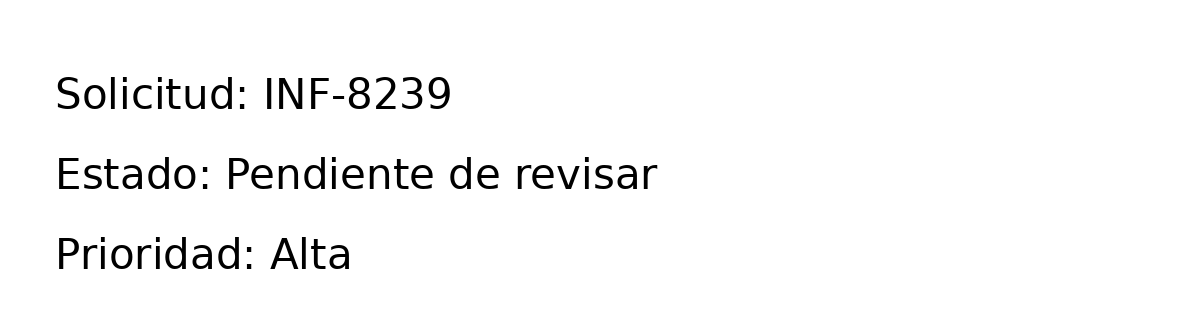

Imagen guardada como documento_demo.png


In [22]:
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont

canvas = Image.new("RGB", (1200, 320), "white")
draw = ImageDraw.Draw(canvas)

font_paths = [
    Path("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"),
    Path("/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf"),
    Path("/usr/share/fonts/opentype/noto/NotoSans-Regular.ttf"),
    Path("C:/Windows/Fonts/arial.ttf"),
]

font = None

for font_path in font_paths:
    if font_path.exists():
        font = ImageFont.truetype(str(font_path), 42)
        print(f"Fuente utilizada: {font_path}")
        break

if font is None:
    print("No se encontró una fuente TrueType. Se utilizará la fuente predeterminada.")
    try:
        font = ImageFont.load_default(size=42)
    except TypeError:
        font = ImageFont.load_default()

draw.text(
    (55, 70),
    "Solicitud: INF-8239",
    fill="black",
    font=font
)

draw.text(
    (55, 150),
    "Estado: Pendiente de revisar",
    fill="black",
    font=font
)

draw.text(
    (55, 230),
    "Prioridad: Alta",
    fill="black",
    font=font
)

display(canvas)
canvas.save("documento_demo.png")

print("Imagen guardada como documento_demo.png")


In [23]:
import cv2
import pytesseract

image = cv2.imread("documento_demo.png")

if image is None:
    raise FileNotFoundError(
        "No fue posible abrir documento_demo.png. "
        "Ejecute primero la celda que crea la imagen."
    )

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

_, binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU #El método de Otsu determina automáticamente un umbral a partir de la distribución de intensidades
)

text = pytesseract.image_to_string(
    binary,
    lang="spa"
)

print(text)


Solicitud: INF-8239
Estado: Pendiente de revisar
Prioridad: Alta



In [24]:
data = pytesseract.image_to_data(binary, lang="spa", output_type=pytesseract.Output.DATAFRAME)
words = data.dropna(subset=["text"])
words = words[words["text"].str.strip().ne("")]
words[["text", "conf"]].reset_index(drop=True)


,text,conf
0,Solicitud:,93.242203
1,INF-8239,90.223457
2,Estado:,96.621986
3,Pendiente,96.649490
4,de,96.935966
5,revisar,96.560043
6,Prioridad:,95.532761
7,Alta,95.671257


In [ ]:
"""
¿Por qué TF-IDF debe ajustarse únicamente con el conjunto de entrenamiento?
¿Qué información aporta F1 macro que podría ocultar la exactitud global?
¿Qué errores lingüísticos podrían ser frecuentes en textos dominicanos?
¿Qué sucedería si OCR reconociera “Prioridad: Alta” como “Prioridad: Baja”?
¿Qué campos deberían exigir revisión humana obligatoria?
¿Cómo se mediría el desempeño de un pipeline que combina OCR y clasificación?
¿Qué riesgos de privacidad existen al procesar documentos reales?
"""